<a href="https://colab.research.google.com/github/mib-a/ML-DL/blob/main/2%20Machine%20Learning/Module%2003%20TTS%20and%20Missing%20Value/3_Train_Test_Split_%26_Imputation.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Starter, Train Test and Handling Missing Values

### Theory Discussed:
- imputation after train_test_split (to prevent data leakage)
- fit_transform for train, only transform for test (to prevent data leakge)
- ravel() and scikit learn 2D array returning (must for categorical)

### Workflow of this file:
- Dataset Loading (titanic_updated.csv)
- dropping unnecessary and target col
- train test split
- missing value imputation  
  - panda : age
  - scikit learn :
    - age: mean, median (no ravel())
    - embarked: ravel ()
    - cabin: indicator

In [172]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer

In [173]:
df = pd.read_csv('titanic_data_updated.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,no,third,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,yes,first,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,yes,third,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,yes,first,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,no,third,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,no,second,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,yes,first,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,no,third,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,yes,first,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


### 3.3 Feature Engineering Starter

#### Dropping Unnecessary Columns

In [174]:
df.drop(['PassengerId','Name','Ticket'],
        axis=1, # columns to be searched.
        inplace=True) # changes will be saved in the main dataset

In [175]:
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,no,third,male,22.0,1,0,7.2500,NaN,S
1,yes,first,female,38.0,1,0,71.2833,C85,C
2,yes,third,female,26.0,0,0,7.9250,NaN,S
3,yes,first,female,35.0,1,0,53.1000,C123,S
4,no,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...
886,no,second,male,27.0,0,0,13.0000,NaN,S
887,yes,first,female,19.0,0,0,30.0000,B42,S
888,no,third,female,NaN,1,2,23.4500,NaN,S
889,yes,first,male,26.0,0,0,30.0000,C148,C


#### Dropping the Label (target column)

In [176]:
X = df.drop(['Survived'],axis=1)
X

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
0,third,male,22.0,1,0,7.2500,NaN,S
1,first,female,38.0,1,0,71.2833,C85,C
2,third,female,26.0,0,0,7.9250,NaN,S
3,first,female,35.0,1,0,53.1000,C123,S
4,third,male,35.0,0,0,8.0500,NaN,S
...,...,...,...,...,...,...,...,...
886,second,male,27.0,0,0,13.0000,NaN,S
887,first,female,19.0,0,0,30.0000,B42,S
888,third,female,NaN,1,2,23.4500,NaN,S
889,first,male,26.0,0,0,30.0000,C148,C


#### Dropping Target Column dataframe

In [177]:
y = df['Survived']
y

,Survived
0,no
1,yes
2,yes
3,yes
4,no
...,...
886,no
887,yes
888,no
889,yes


### 3.5 Train Test Split Code

In [178]:
X_train, X_test, y_train, y_test = train_test_split(X,y,
                                                    test_size=0.2, # 20% of total data will be used for testing
                                                    random_state=42) # for reproducibility

#### Display & Print X/y_train/test

In [179]:
print(f"y_train: \n{y_train}\n")
display(X_train)
# print(f"X_test: \n{X_test}\n")
# print(f"y_test: \n{y_test}\n")

y_train: 
331     no
733     no
382     no
704     no
813     no
      ... 
106    yes
270     no
860     no
435    yes
102     no
Name: Survived, Length: 712, dtype: object



,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.5,0,0,28.5000,C124,S
733,second,male,23.0,0,0,13.0000,NaN,S
382,third,male,32.0,0,0,7.9250,NaN,S
704,third,male,26.0,1,0,7.8542,NaN,S
813,third,female,6.0,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.0,0,0,7.6500,NaN,S
270,first,male,NaN,0,0,31.0000,NaN,S
860,third,male,41.0,2,0,14.1083,NaN,S
435,first,female,14.0,1,2,120.0000,B96 B98,S


#### Note: Imputation after train_test-split
In imputation, we use mean, median, standard deviation etc. If you impute the whole dataset before tts, model will be able to see through all those test data and will encounter a data leakage. Your model's predictions on this exact dataset will be exceptionally well but on any unseen data it won't be ab;e to predict anything as it has learnt zero thing (overfitting).

### 3.7 Numerical Imputation with Pandas

#### Checkin for null values in X_train/test

In [180]:
X_train.isnull().sum()

,0
Pclass,0
Sex,0
Age,140
SibSp,0
Parch,0
Fare,0
Cabin,553
Embarked,2


In [181]:
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,37
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0


#### Visualize Age before Imputation

<Axes: xlabel='Age', ylabel='Density'>

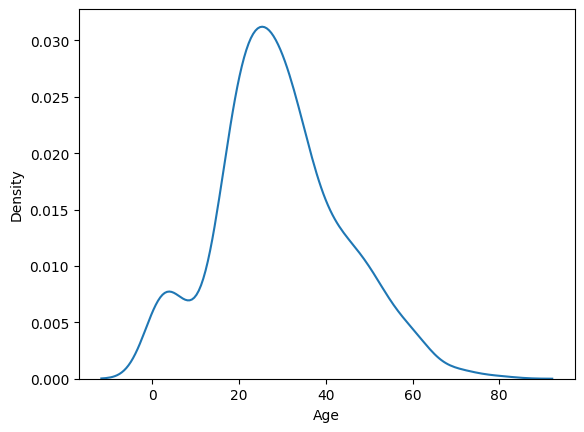

In [182]:
sns.kdeplot(data = X_train, x = "Age")

#### Imputing age with mean value

In [183]:
#mean impute

age_mean = X_train['Age'].mean() # mean of age col of X_train

# df["new_col"] = df["present_col"].fillna(age_mean) : fillna = fill all the values which are NaN (missing)

# impute both of X_train, y_train
X_train['age_mean_imputor'] = X_train['Age'].fillna(age_mean)
X_test['age_mean_imputor'] = X_test['Age'].fillna(age_mean)

<Axes: xlabel='age_mean_imputor', ylabel='Density'>

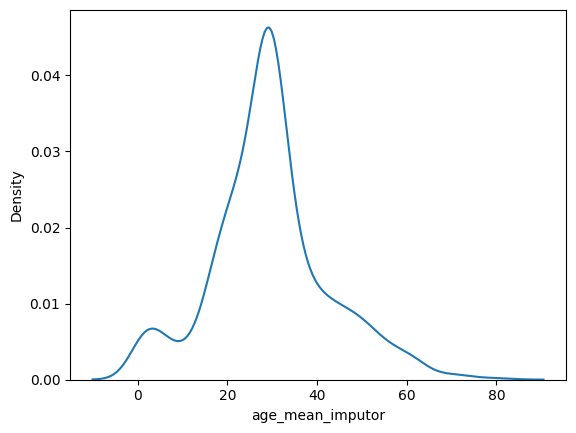

In [184]:
sns.kdeplot(data = X_train, x = "age_mean_imputor")

#### Imputing age with median

In [185]:
#median impute

age_median = X_train['Age'].median()

X_train['age_median_imputor'] = X_train['Age'].fillna(age_median)

X_test['age_median_imputor'] = X_test['Age'].fillna(age_median)

<Axes: xlabel='age_median_imputor', ylabel='Density'>

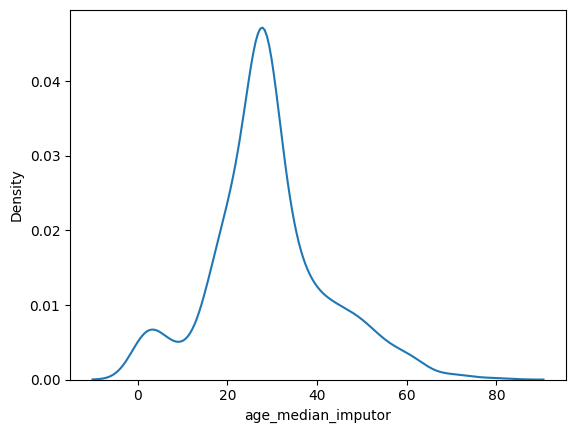

In [186]:
sns.kdeplot(data = X_train, x = "age_median_imputor")

### 3.8 Numerical Imputation Simple Imputer

In [187]:
from sklearn.impute import SimpleImputer

age_imputer = SimpleImputer(missing_values=np.nan , strategy='mean') # ~= fillna (df[""].mean)
X_train["Age"] = age_imputer.fit_transform(X_train[["Age"]])

X_train.sample(2)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,age_mean_imputor,age_median_imputor
526,second,female,50.0,0,0,10.50,NaN,S,50.0,50.0
749,third,male,31.0,0,0,7.75,NaN,Q,31.0,31.0


Explanation: Age and age_mean_imputer are the same, same goes for median. You can change mean to median and compare it with age_median_imputor

#### The less cols (= the less dimensions) the better

In [188]:
print(f"Num of sum values in Age: {X_train.isnull().sum()}")

# dropping unnecessary cols
X_train.drop(['age_mean_imputor','age_median_imputor'],axis=1,inplace=True)

X_train

Num of sum values in Age: Pclass                  0
Sex                     0
Age                     0
SibSp                   0
Parch                   0
Fare                    0
Cabin                 553
Embarked                2
age_mean_imputor        0
age_median_imputor      0
dtype: int64


,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
331,first,male,45.500000,0,0,28.5000,C124,S
733,second,male,23.000000,0,0,13.0000,NaN,S
382,third,male,32.000000,0,0,7.9250,NaN,S
704,third,male,26.000000,1,0,7.8542,NaN,S
813,third,female,6.000000,4,2,31.2750,NaN,S
...,...,...,...,...,...,...,...,...
106,third,female,21.000000,0,0,7.6500,NaN,S
270,first,male,29.498846,0,0,31.0000,NaN,S
860,third,male,41.000000,2,0,14.1083,NaN,S
435,first,female,14.000000,1,2,120.0000,B96 B98,S


#### Note: Fit & Transform
- Fit : going through the whole model, learning it's mean, median etc from the dataset.
- Transform : as the direction of simple imputer, it will transform the dataset with that learnt statistics (like imputing *missing values* with *mean / median*)

- Problem: We do fit only on the train data as model can see it, can learn necessary statistics from it. Train and test datasets have a very little difference in their statistics. Almost identical. So, the model learn the statistics from the training data and use it to transform both train and test data. if you fit the test data too, the model will be able to see the test dataset,and same as before data leakage will occur.



In [189]:
X_test['Age'] = age_imputer.transform(X_test[['Age']])

X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0
age_mean_imputor,0
age_median_imputor,0


In [190]:
X_test.drop(['age_mean_imputor','age_median_imputor'],axis=1,inplace=True)
X_test

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked
709,third,male,29.498846,1,1,15.2458,NaN,C
439,second,male,31.000000,0,0,10.5000,NaN,S
840,third,male,20.000000,0,0,7.9250,NaN,S
720,second,female,6.000000,0,1,33.0000,NaN,S
39,third,female,14.000000,1,0,11.2417,NaN,C
...,...,...,...,...,...,...,...,...
433,third,male,17.000000,0,0,7.1250,NaN,S
773,third,male,29.498846,0,0,7.2250,NaN,C
25,third,female,38.000000,1,5,31.3875,NaN,S
84,second,female,17.000000,0,0,10.5000,NaN,S


### 3.9 Categorical Value Imputation

#### Imputing with mode (most frequent)

In [191]:
embarked_imputer = SimpleImputer(missing_values=np.nan , strategy='most_frequent')

X_train['Embarked'] = embarked_imputer.fit_transform(X_train[['Embarked']]).ravel()
X_test['Embarked'] = embarked_imputer.transform(X_test[['Embarked']]).ravel()

#### Note: `ravel():`
Scikit-Learn expects and returns a 2D array, series (columns) of pandas are 1D arrays. So,

`df[col] = imputer.fit_transform(df[["col"]]).ravel()`
- `df[['col']]` : turning the col into 2D array by double [], so scikit learn can work with that.
- `.ravel()` : pandas can not work with 2D and scikit returned 2D array, so to ***flatten*** it to 1D, we use ravel()

Exception:
- sometimes **numerical columns** *(age)* or integer type categorical columns *doesnt need `.ravel()`*. Panda converts them itself. But still it can throw some errors or warning. Completely depends on pandas version. But for a categorical col, you will always need ravel (*embarked*)

In [192]:
X_train.isnull().sum()
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,134
Embarked,0


#### Imputing with constant and indicator

In [194]:
cabin_imputer = SimpleImputer(missing_values=np.nan, # which to impute: all the NaN (nan) values
                              strategy='constant', # by what strategy to impute: use a constant
                              fill_value='Missing', # what constant? : most frequent (mode) / "missing"
                              add_indicator=True) # add another col to address which rows had NaN values

# fit & or transform into two columns because add_indicator=True returns both imputed values and indicators
X_train[['Cabin', 'cabin_missing_indicator']] = cabin_imputer.fit_transform(X_train[['Cabin']])
X_test[['Cabin', 'cabin_missing_indicator']] = cabin_imputer.transform(X_test[['Cabin']])

X_train.sample(5)

,Pclass,Sex,Age,SibSp,Parch,Fare,Cabin,Embarked,cabin_missing_indicator
129,third,male,45.000000,0,0,6.9750,Missing,S,True
638,third,female,41.000000,0,5,39.6875,Missing,S,True
576,second,female,34.000000,0,0,13.0000,Missing,S,True
240,third,female,29.498846,1,0,14.4542,Missing,C,True
380,first,female,42.000000,0,0,227.5250,Missing,C,True


Check for null values again

In [195]:
X_train.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
cabin_missing_indicator,0


In [196]:
X_test.isnull().sum()

,0
Pclass,0
Sex,0
Age,0
SibSp,0
Parch,0
Fare,0
Cabin,0
Embarked,0
cabin_missing_indicator,0
